# Backtest Autopsy #3: a CUSUM and rolling-ADF regime router for six FX pairs, starved of regime events

**Tags:** regime starvation (primary), cost model (secondary)

## TL;DR

* **Idea.** On six USD FX pairs, a causal CUSUM detector marks "trend" regimes and a rolling Augmented Dickey-Fuller (ADF) test on the residual of a pair against a related pair marks "mean-reversion" regimes. A router then trades a moving-average direction in trend regimes, fades the residual in mean-reversion regimes, and stays flat when the two disagree or neither fires.
* **Result.** Over the development window, on 100,000 USD of illustrative equity, the plain moving-average baseline returns **-37.9%** net and the routed strategy **-27.4%** (annualised Sharpe -1.16 and -0.97). Neither has an edge after executable prices: the 95% interval of the mean daily return is below zero for both.
* **Verdict number.** The mean-reversion branch, the only part that is new, produced **17 development trades** against a minimum of 30 per regime fixed in advance. The mean-reversion regime occupies only 7 to 35 days per pair (0.3% to 1.3% of all days), and each episode lasts 1 to 16 days. With 17 trades the smallest edge the data could detect is about 32 basis points per trade; an edge of 5 basis points would need roughly 705 trades.
* **Why it matters.** The hypothesis (route by regime) cannot be tested when one of its two regimes almost never occurs. The data did not say "mean reversion does not work"; it said "there is nothing to estimate".

> Outputs below come from a run on the real data. With `AUTOPSY_SYNTHETIC=1` the notebook runs end to end on a synthetic quote panel with the same schema and will **not** reproduce the failure.

### Prerequisites

* Python 3.10+, `numpy`, `pandas`, `scipy`, `statsmodels`, `matplotlib`, `pyarrow`, and the shared package `autopsy_common` (`pip install -e ../..`).
* Familiarity with: bid/ask quotes and executable fills, the CUSUM change detector, the ADF unit-root test and its half-life reading, multiple-comparison corrections (Bonferroni), and why an out-of-sample record needs enough independent events.
* Data: your own minute-level bid/ask FX file described in section 2, in a folder named by `AUTOPSY_DATA_DIR`. No data is shipped with this repository.

## 1. Settings (control panel)

One dictionary holds every governing constant. The values below are the starting point for this case. Change them and re-run the test to see whether the verdict holds; the README lists the implementation notes. Two environment variables select the mode:

* `AUTOPSY_SYNTHETIC=1` builds a synthetic quote panel (same schema, no vendor data).
* `AUTOPSY_DATA_DIR` points at the folder holding your minute-level FX file.

Design notes on the constants:

* The moving-average pair is **9 / 37**. The baseline is only a direction rule; its exact horizons are not the point.
* The CUSUM and ADF constants were fixed before any result was looked at (they are fixed constants): no search was run, and none is run here.
* The ADF significance level is divided by the number of related-pair candidates (six) with a Bonferroni correction, and a mean-reversion call also needs a half-life between two and sixty days and five consecutive passing days.
* The development window is the evidence; everything from the holdout start onward is **retrospective** (it had been looked at before), never used for any choice, and reported separately.

In [ ]:
from __future__ import annotations

import json
import math
import os
import time
import warnings
from pathlib import Path
from typing import Any, Dict, List, Mapping, Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from autopsy_common.data import use_synthetic
from autopsy_common.metrics import block_bootstrap_sharpe, bootstrap_mean_ci
from autopsy_common.perf import performance_summary
from autopsy_common.plots import (plot_bar_contribution, plot_capital_sweep, plot_drawdown, plot_equity,
                                  plot_exposure_turnover, plot_monthly_heatmap, plot_return_distribution,
                                  plot_rolling_risk, plot_yearly_bars)
from autopsy_common.regimes import run_length_table
from autopsy_common.schema import check_schema
from autopsy_common.sweep import capital_sweep

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
SYNTHETIC = use_synthetic()
DATA_DIR = Path(os.environ["AUTOPSY_DATA_DIR"]) if os.environ.get("AUTOPSY_DATA_DIR") else None
RAW_FILE = "merged_forex_data_with_xauusd.csv"     # wide minute-level bid/ask file (see section 2)
DAILY_FILE = "fx_daily_bid_ask.parquet"            # daily cache built by this notebook if absent
RESULTS: Dict[str, Any] = {}

PAIRS = ("EURUSD", "GBPUSD", "AUDUSD", "USDCAD", "USDCHF", "USDJPY")
# Six related-pair candidates for the residual test, fixed in advance; no candidate search occurs.
HEDGE_PAIR: Mapping[str, str] = {"EURUSD": "GBPUSD", "GBPUSD": "EURUSD", "AUDUSD": "EURUSD",
                                 "USDCAD": "USDCHF", "USDCHF": "USDCAD", "USDJPY": "USDCHF"}

PARAMS: Dict[str, Any] = dict(
    capital=100_000.0,                  # illustrative initial equity in USD (an assumption; see the capital sweep)
    development_start="2018-01-01",      # first day of the development window
    holdout_start="2025-01-01",          # first day of the retrospective window (never used for any choice)
    warmup_days=300,                     # calendar days of history loaded before the development window

    # baseline direction rule: fast/slow moving averages of the mid close (the pair this case tests)
    ma_fast=9, ma_slow=37,

    # causal CUSUM on standardised returns
    cusum_window=60, cusum_drift=0.50, cusum_threshold=5.0, cusum_cooldown=5, trend_strength_min=0.50,

    # rolling ADF on the residual of a pair against its fixed related pair
    adf_window=120, adf_max_lag=1, adf_alpha=0.05, adf_min_half_life=2.0, adf_max_half_life=60.0,
    regime_min_duration=5, mr_entry_z=1.5,

    # costs: executable bid/ask prices (spread) plus a flat commission add-on per order
    commission_bps_per_order=0.50, cost_multiplier=1.0,

    # hurdles of the decision rule, fixed in advance
    min_trades=120, min_conditional_trades=30, stability_min=0.60,

    # reporting
    n_bootstrap=2000, random_seed=11, trading_days=252,
)
print(f"mode: {'SYNTHETIC' if SYNTHETIC else 'REAL DATA'} | pairs: {len(PAIRS)} | MA pair: "
      f"{PARAMS['ma_fast']}/{PARAMS['ma_slow']}")

mode: REAL DATA | pairs: 6 | MA pair: 9/37


## 2. Data

### 2.1 Source recipe

| Item | Value |
|---|---|
| Vendor / product | Interactive Brokers historical data API, FX contracts, `BID` and `ASK` bar series (terms of use: verify before publishing any value) |
| Instruments | six USD pairs: EURUSD, GBPUSD, AUDUSD, USDCAD, USDCHF, USDJPY |
| Frequency | 1 minute (raw), collapsed to one daily bid/ask close per pair |
| Time zone | naive timestamps in a fixed UTC-5 offset (no daylight saving) |

**How to rebuild.** The raw file is one wide table with a `timestamp` column and, for every pair, a `<PAIR>_final_df__bid_close` and a `<PAIR>_final_df__ask_close` column (the file also carries open, high and low columns that this case does not use). Any provider that gives one-minute bid and ask closes for the six pairs can be pivoted into that shape. The notebook reads it in chunks, sorts by timestamp, keeps the last row of any duplicated timestamp and collapses each pair to its last valid bid and ask of each calendar day, then caches the result next to the raw file as a small parquet.

### 2.2 What the strategy consumes: the daily quote panel

* **Row definition.** One row is one pair on one calendar day: the last bid close and last ask close observed that day.
* **Key.** `(date, asset)`, unique. **Sort order.** by `date` then `asset`, ascending.
* **Nulls.** Rows with a missing bid or ask are dropped before the daily collapse; the panel has none. A pair can therefore have a different set of dates from another pair, and the pipeline aligns pairs only where it needs to (the ADF leg).
* **Executable prices.** A long fills at the ask and exits at the bid; a short fills at the bid and exits at the ask. The mid close (average of bid and ask) is used only for signals.

| Column | dtype | Meaning | Units |
|---|---|---|---|
| `date` | datetime | calendar day of the daily bar | day |
| `asset` | string | pair label | n/a |
| `bid_close` | float64 | last bid close of the day | quote currency |
| `ask_close` | float64 | last ask close of the day | quote currency |

Synthetic mode produces a panel with the same columns: driftless random walks with a shared factor and a small constant spread.

In [ ]:
DAILY_SCHEMA = {"date": "datetime", "asset": "string", "bid_close": "float64", "ask_close": "float64"}
DAILY_KEY = ["date", "asset"]


def read_minute_quotes(csv_path: Path, pairs, start: pd.Timestamp, chunksize: int = 300_000) -> pd.DataFrame:
    """Minute-level loader: read only `timestamp` and the bid/ask
    closes of the requested pairs in chunks, skip chunks wholly before `start`, then sort by timestamp and
    keep the last row of any duplicated timestamp."""
    usecols = ["timestamp"] + [f"{p}_final_df__{side}_close" for p in pairs for side in ("bid", "ask")]
    parts = []
    for chunk in pd.read_csv(csv_path, usecols=usecols, chunksize=chunksize):
        chunk["timestamp"] = pd.to_datetime(chunk["timestamp"], errors="coerce")
        chunk = chunk.dropna(subset=["timestamp"])
        if chunk.empty or chunk["timestamp"].max() < start:
            continue
        parts.append(chunk[chunk["timestamp"] >= start])
    if not parts:
        raise RuntimeError("no minute rows after the requested start")
    raw = pd.concat(parts, ignore_index=True)
    return raw.sort_values("timestamp").drop_duplicates("timestamp", keep="last").reset_index(drop=True)


def daily_from_minute(raw: pd.DataFrame, pairs) -> pd.DataFrame:
    """Last valid bid and ask close of each calendar day, one block of rows per pair."""
    frames = []
    for pair in pairs:
        bid, ask = f"{pair}_final_df__bid_close", f"{pair}_final_df__ask_close"
        src = raw[["timestamp", bid, ask]].dropna(subset=[bid, ask])
        day = src["timestamp"].dt.normalize().rename("date")
        daily = src.groupby(day, sort=True).agg(bid_close=(bid, "last"), ask_close=(ask, "last")).reset_index()
        daily.insert(1, "asset", pair)
        frames.append(daily)
    out = pd.concat(frames, ignore_index=True)
    out["bid_close"] = out["bid_close"].astype("float64")
    out["ask_close"] = out["ask_close"].astype("float64")
    return out.sort_values(DAILY_KEY).reset_index(drop=True)


def synthetic_quotes(pairs, n_days: int = 2400, seed: int = 5, start: str = "2017-03-07") -> pd.DataFrame:
    """Synthetic daily bid/ask closes: driftless random walks with a shared factor. No edge by construction."""
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range(start, periods=n_days)
    common = rng.normal(0.0, 0.003, n_days)
    frames = []
    for i, pair in enumerate(pairs):
        level = (1.1, 1.3, 0.7, 1.3, 0.9, 110.0)[i % 6]
        ret = rng.normal(0.0, 0.005, n_days) + common
        mid = level * np.exp(np.cumsum(ret))
        half = mid * 0.00005
        frames.append(pd.DataFrame({"date": dates, "asset": pair, "bid_close": np.round(mid - half, 6),
                                    "ask_close": np.round(mid + half, 6)}))
    return pd.concat(frames, ignore_index=True).sort_values(DAILY_KEY).reset_index(drop=True)


def load_daily(p: Dict[str, Any]) -> pd.DataFrame:
    if SYNTHETIC:
        df = synthetic_quotes(PAIRS)
    else:
        if DATA_DIR is None:
            raise RuntimeError("Set AUTOPSY_SYNTHETIC=1, or AUTOPSY_DATA_DIR to the folder with the minute FX file.")
        cache = DATA_DIR / DAILY_FILE
        if cache.exists():
            df = pd.read_parquet(cache)
        else:
            start = pd.Timestamp(p["development_start"]) - pd.Timedelta(days=int(p["warmup_days"]))
            df = daily_from_minute(read_minute_quotes(DATA_DIR / RAW_FILE, PAIRS, start), PAIRS)
            df.to_parquet(cache, index=False)
        df = df.sort_values(DAILY_KEY).reset_index(drop=True)
    df = df[list(DAILY_SCHEMA)]
    check_schema(df, DAILY_SCHEMA, DAILY_KEY)
    return df


DAILY = load_daily(PARAMS)
print("schema check passed:", True)
print("key unique:", not bool(DAILY.duplicated(DAILY_KEY).any()),
      "| sorted:", bool(DAILY.sort_values(DAILY_KEY).index.equals(DAILY.index)))
print("no nulls in bid_close, ask_close:", not bool(DAILY[["bid_close", "ask_close"]].isna().any().any()))
print("no crossed quotes (ask >= bid):", bool((DAILY["ask_close"] >= DAILY["bid_close"]).all()))
print("pairs present:", sorted(DAILY["asset"].unique()) == sorted(PAIRS))

schema check passed: True
key unique: True | sorted: True
no nulls in bid_close, ask_close: True
no crossed quotes (ask >= bid): True
pairs present: True


## 3. Step 1: the daily frame and the baseline direction rule

For every pair the mid close is `(bid + ask) / 2`. The **baseline** is deliberately dull: the sign of `fast MA - slow MA` of the mid close (long when the fast average is above the slow one, short otherwise, flat until both exist). It is the direction the trend regime will trade, and it is also the benchmark that every regime gate must beat.

Two more per-day ingredients are built here: `vol_20`, the trailing 20-day standard deviation of daily returns, and the **trend strength** `|fast MA - slow MA| / (close x vol_20)`, a unit-free measure of how far apart the two averages are in daily-volatility units. A trend call will later need a strength of at least 0.5.

Every column at row `t` uses data up to and including day `t`. What can go wrong: a moving average with `min_periods` shorter than its window would emit a direction before the window was full.

In [ ]:
def make_pair_frame(daily_pair: pd.DataFrame, p: Dict[str, Any]) -> pd.DataFrame:
    f = daily_pair.set_index("date").sort_index()[["bid_close", "ask_close"]].copy()
    f["close"] = 0.5 * (f["bid_close"] + f["ask_close"])
    f["ret_1"] = f["close"].pct_change()
    f["fast_ma"] = f["close"].rolling(p["ma_fast"], min_periods=p["ma_fast"]).mean()
    f["slow_ma"] = f["close"].rolling(p["ma_slow"], min_periods=p["ma_slow"]).mean()
    f["baseline_signal"] = np.sign(f["fast_ma"] - f["slow_ma"])
    f["vol_20"] = f["ret_1"].rolling(20, min_periods=20).std(ddof=0)
    return f


def make_frames(daily: pd.DataFrame, p: Dict[str, Any]) -> Dict[str, pd.DataFrame]:
    return {pair: make_pair_frame(daily.loc[daily["asset"] == pair], p) for pair in PAIRS}


FRAMES = make_frames(DAILY, PARAMS)
print("pair frames:", len(FRAMES), "| columns:", list(FRAMES[PAIRS[0]].columns))

pair frames: 6 | columns: ['bid_close', 'ask_close', 'close', 'ret_1', 'fast_ma', 'slow_ma', 'baseline_signal', 'vol_20']


## 4. Step 2: the causal CUSUM trend detector

CUSUM accumulates standardised surprises until they cross a threshold. The pipeline:

1. Daily log return, standardised by the **prior** 60-day mean and standard deviation (both shifted one day, so day `t` never standardises itself) and clipped at +/-10.
2. Two running sums, `pos = max(0, pos + z - drift)` and `neg = min(0, neg + z + drift)`, with drift 0.5. An **event** fires when `pos > 5` or `neg < -5`; both sums reset to zero after an event.
3. `cusum_days_since_event` counts days since the last event. A **trend support** flag needs a baseline direction, a trend strength of at least 0.5, at least 5 days since the last event (the cooldown) and **five consecutive days** of all three (a persistence filter, so a single day cannot flip a regime).

What can go wrong: the persistence filter is a hysteresis, which makes the regime sticky by construction. That is intended, but it also means the number of regime *episodes* is much smaller than the number of regime *days*.

In [ ]:
def cusum_features(frame: pd.DataFrame, p: Dict[str, Any]) -> pd.DataFrame:
    """Causal two-sided CUSUM of returns standardised from prior observations only."""
    out = pd.DataFrame(index=frame.index)
    w = int(p["cusum_window"])
    ret = np.log(frame["close"]).diff()
    mean = ret.rolling(w, min_periods=w).mean().shift(1)
    std = ret.rolling(w, min_periods=w).std(ddof=0).shift(1)
    z = ((ret - mean) / std.replace(0.0, np.nan)).clip(-10.0, 10.0)
    pos, neg, events, direction = 0.0, 0.0, [], []
    for value in z.to_numpy(dtype=float):
        if not np.isfinite(value):
            events.append(False)
            direction.append(0)
            continue
        pos = max(0.0, pos + value - p["cusum_drift"])
        neg = min(0.0, neg + value + p["cusum_drift"])
        event = pos > p["cusum_threshold"] or neg < -p["cusum_threshold"]
        sign = 1 if pos > p["cusum_threshold"] else (-1 if neg < -p["cusum_threshold"] else 0)
        events.append(event)
        direction.append(sign)
        if event:
            pos = neg = 0.0
    out["return_z_prior_window"] = z
    out["cusum_event"] = events
    out["cusum_direction"] = direction
    days_since, elapsed = [], 10_000
    for event in out["cusum_event"].to_numpy(dtype=bool):
        elapsed = 0 if event else elapsed + 1
        days_since.append(elapsed)
    out["cusum_days_since_event"] = days_since
    ma_strength = (frame["fast_ma"] - frame["slow_ma"]).abs() / (frame["close"] * frame["vol_20"].replace(0.0, np.nan))
    out["ma_signal"] = frame["baseline_signal"].fillna(0).astype(int)
    out["ma_strength_vol_units"] = ma_strength
    raw_trend = ((out["ma_signal"] != 0) & (ma_strength >= p["trend_strength_min"])
                 & (out["cusum_days_since_event"] >= p["cusum_cooldown"]))
    streak = raw_trend.groupby((~raw_trend).cumsum()).cumcount() + 1
    out["cusum_trend_support"] = raw_trend & (streak >= p["regime_min_duration"])
    return out


t0 = time.time()
CUSUM = {pair: cusum_features(FRAMES[pair], PARAMS) for pair in PAIRS}
print(f"CUSUM features built for {len(CUSUM)} pairs in {time.time() - t0:.1f}s")
print("events per pair:", {k: int(v["cusum_event"].sum()) for k, v in CUSUM.items()})

CUSUM features built for 6 pairs in 0.0s
events per pair: {'EURUSD': 17, 'GBPUSD': 15, 'AUDUSD': 15, 'USDCAD': 13, 'USDCHF': 20, 'USDJPY': 27}


## 5. Step 3: the rolling ADF mean-reversion detector

For each pair `y` the code pairs it with one fixed related pair `x` (for example EURUSD with GBPUSD). On each day it uses **only the trailing 120 observations through that day**:

1. Fit `log y = a + b log x` by least squares and take the residual series.
2. Run an ADF test with a constant and one lagged difference on the residual. A small p-value says the residual is stationary, that is, `y` and `x` are cointegrated over this window.
3. Estimate the residual's **half-life** from `delta r = c + beta r_lag`: `-ln 2 / beta` when `beta < 0`, infinite otherwise. Only half-lives between 2 and 60 days are accepted.
4. Record the residual's z-score against the window.

A day is "stationary" when `p < alpha / 6` (Bonferroni over the six related pairs: 0.05 / 6 = 0.0083) **and** the half-life is in bounds. A **mean-reversion support** flag needs five consecutive stationary days.

This is the expensive step (one regression and one ADF per pair per day). What can go wrong: a rolling cointegration test run daily on a 120-day window is a multiple-testing machine; the Bonferroni correction covers the six pairs but not the thousand overlapping windows, so a hit is rare and, when it comes, is not independent of the next day's.

In [ ]:
from statsmodels.tsa.stattools import adfuller


def half_life(values: np.ndarray) -> float:
    lag, delta = values[:-1], np.diff(values)
    if len(lag) < 3 or np.std(lag) == 0:
        return np.nan
    beta = float(np.linalg.lstsq(np.column_stack([np.ones(len(lag)), lag]), delta, rcond=None)[0][1])
    return float(-math.log(2.0) / beta) if beta < 0 else np.inf


def rolling_adf(anchor_close: pd.Series, hedge_close: pd.Series, p: Dict[str, Any]) -> pd.DataFrame:
    """Fit y = a + b x and test its residual using only the trailing window through t."""
    aligned = pd.concat([np.log(anchor_close).rename("y"), np.log(hedge_close).rename("x")], axis=1).dropna()
    window, n = int(p["adf_window"]), len(aligned)
    names = ["hedge_ratio", "adf_p_value", "adf_stat", "half_life_days", "residual", "residual_z"]
    cols = {k: np.full(n, np.nan) for k in names}
    yv, xv = aligned["y"].to_numpy(), aligned["x"].to_numpy()
    for end in range(window - 1, n):
        x, y = xv[end - window + 1:end + 1], yv[end - window + 1:end + 1]
        design = np.column_stack([np.ones(window), x])
        intercept, beta = np.linalg.lstsq(design, y, rcond=None)[0]
        residuals = y - intercept - beta * x
        result = adfuller(residuals, maxlag=int(p["adf_max_lag"]), regression="c", autolag=None)
        sigma = residuals.std(ddof=1)
        cols["hedge_ratio"][end] = beta
        cols["adf_p_value"][end] = float(result[1])
        cols["adf_stat"][end] = float(result[0])
        cols["half_life_days"][end] = half_life(residuals)
        cols["residual"][end] = float(residuals[-1])
        cols["residual_z"][end] = (residuals[-1] - residuals.mean()) / sigma if sigma > 0 else np.nan
    return pd.DataFrame(cols, index=aligned.index).reindex(anchor_close.index)


t0 = time.time()
ADF = {pair: rolling_adf(FRAMES[pair]["close"], FRAMES[HEDGE_PAIR[pair]]["close"], PARAMS) for pair in PAIRS}
RESULTS["adf_wall_s"] = time.time() - t0
print(f"rolling ADF done for {len(ADF)} pairs in {RESULTS['adf_wall_s']:.0f}s")

rolling ADF done for 6 pairs in 6s


## 6. Step 4: regime classification and the four signals

With the detectors stored, the regime logic is cheap and is kept separate so that a sensitivity run does not repeat the ADF. For each pair-day:

* **regime** = `mean_reversion` if the ADF support flag is on and the trend flag is off; `trend` if the trend flag is on and the ADF flag is off; otherwise `uncertain_flat`. When both fire, the day is **uncertain** and the router stays flat.
* **Four signals**, all decided at the close of day `t` and traded over `t` to `t+1`:
  1. `baseline_ma`: the moving-average direction, always on.
  2. `cusum_regime_gate`: the moving-average direction, only in trend regimes.
  3. `adf_regime_gate`: fade the residual (short when its z-score is at least +1.5, long when at most -1.5) whenever the ADF support flag is on, regardless of the trend flag.
  4. `combined_cusum_adf_routing`: moving-average direction in `trend`, fade the residual in `mean_reversion` (when |z| >= 1.5), flat otherwise.

The residual z-score of a pair against its related pair is a *spread* signal; the position is taken in the anchor pair only (long the anchor when the residual is unusually low), which is how the strategy is defined here.

In [ ]:
STRATEGIES = {"baseline_ma": "signal_baseline_ma", "cusum_regime_gate": "signal_cusum_gate",
              "adf_regime_gate": "signal_adf_gate", "combined_cusum_adf_routing": "signal_combined_cusum_adf"}


def classify(joined: pd.DataFrame, p: Dict[str, Any], adjusted_alpha: Optional[float] = None,
             min_half_life: Optional[float] = None, max_half_life: Optional[float] = None) -> pd.DataFrame:
    """Regime labels and the four signals from stored detector columns. The ADF significance level is the
    Bonferroni-adjusted one unless a different per-test level is passed (used only by the sensitivity table)."""
    lo = p["adf_min_half_life"] if min_half_life is None else min_half_life
    hi = p["adf_max_half_life"] if max_half_life is None else max_half_life
    alpha = (p["adf_alpha"] / len(HEDGE_PAIR)) if adjusted_alpha is None else adjusted_alpha
    out = joined.copy()
    stationary = (out["adf_p_value"] < alpha) & out["half_life_days"].between(lo, hi)
    streak = stationary.groupby((~stationary).cumsum()).cumcount() + 1
    out["adf_stationary"] = stationary
    out["adf_mean_reversion_support"] = stationary & (streak >= p["regime_min_duration"])
    trend, mr = out["cusum_trend_support"], out["adf_mean_reversion_support"]
    out["regime"] = np.select([mr & ~trend, trend & ~mr], ["mean_reversion", "trend"], default="uncertain_flat")
    z = out["residual_z"]
    fade = -np.sign(z)
    entry = z.abs() >= p["mr_entry_z"]
    out["signal_baseline_ma"] = out["ma_signal"]
    out["signal_cusum_gate"] = np.where(trend, out["ma_signal"], 0)
    out["signal_adf_gate"] = np.where(mr & entry, fade, 0).astype(int)
    out["signal_combined_cusum_adf"] = np.select(
        [out["regime"].eq("trend"), out["regime"].eq("mean_reversion") & entry], [out["ma_signal"], fade],
        default=0).astype(int)
    return out


def build_regime_frames(frames, cusum, adf, p, adjusted_alpha=None) -> Dict[str, pd.DataFrame]:
    out = {}
    for pair in PAIRS:
        joined = pd.concat([frames[pair][["close", "bid_close", "ask_close"]], cusum[pair], adf[pair]], axis=1)
        out[pair] = classify(joined, p, adjusted_alpha=adjusted_alpha)
    return out


REGIMES = build_regime_frames(FRAMES, CUSUM, ADF, PARAMS)
share = pd.DataFrame({pair: f["regime"].value_counts(normalize=True) for pair, f in REGIMES.items()}).fillna(0.0).T
print("share of days by regime (%), whole loaded history including the warm-up:")
display((share * 100).round(1))

share of days by regime (%), whole loaded history including the warm-up:


regime,trend,uncertain_flat,mean_reversion
EURUSD,69.9,28.9,1.2
GBPUSD,73.0,25.9,1.1
AUDUSD,72.1,27.7,0.2
USDCAD,69.0,30.2,0.8
USDCHF,66.6,32.4,1.0
USDJPY,68.1,31.5,0.4


## 7. Step 5: one-bar executable trades, costs and the equity record

Every pair-day with a non-zero signal is a **one-bar round trip**: enter at the executable price of day `t` and exit at the executable price of day `t+1`. A long buys at the ask and sells at the bid; a short sells at the bid and buys back at the ask. A flat commission add-on of 0.5 basis points per order (two orders per round trip) is charged on top. The bid/ask spread is therefore already inside every return.

The portfolio return of a day is the **sum of the pair returns divided by six** (each pair is given one sixth of equity as notional; a pair with no signal contributes zero, so gross exposure never exceeds 1x equity). It is a return-space strategy: position size is a fixed share of equity per pair, so equity in USD is `capital x cumulative product (1 + portfolio return)`, and every ratio is independent of the capital (section 11 makes that explicit).

**Development versus retrospective.** A trade whose entry is in the development window but whose exit would fall in the holdout window is dropped, so no development number touches a retrospective price.

The strategy treats a signal at the close of day `t` as executable at that same close: a model simplification, not evidence of live fill quality. It is kept, and flagged again in the caveats.

In [ ]:
def trade_table(regimes: Mapping[str, pd.DataFrame], p: Dict[str, Any]) -> pd.DataFrame:
    """One row per pair, day and strategy; the return is for the one-bar hold from t to t+1."""
    cost = 2.0 * p["commission_bps_per_order"] * p["cost_multiplier"] / 10_000.0
    start, holdout = pd.Timestamp(p["development_start"]), pd.Timestamp(p["holdout_start"])
    rows = []
    for pair, f in regimes.items():
        exit_date = pd.Series(f.index, index=f.index).shift(-1)
        valid = exit_date.notna() & (f.index >= start)
        period = pd.Series(np.where(f.index < holdout, "development", "retrospective"), index=f.index)
        valid &= ~((period == "development") & (exit_date >= holdout))
        bid_n, ask_n, close_n = f["bid_close"].shift(-1), f["ask_close"].shift(-1), f["close"].shift(-1)
        long_ret = bid_n / f["ask_close"] - 1.0
        short_ret = f["bid_close"] / ask_n - 1.0
        for name, col in STRATEGIES.items():
            side = f[col].fillna(0).astype(int)
            exec_ret = np.where(side > 0, long_ret, np.where(side < 0, short_ret, 0.0))
            traded = side != 0
            net = np.where(traded, exec_ret - cost, 0.0)
            mid = np.where(traded, side * (close_n / f["close"] - 1.0), 0.0)
            part = pd.DataFrame({"date": f.index, "exit_date": exit_date.to_numpy(), "period": period.to_numpy(),
                                 "pair": pair, "strategy": name, "side": side.to_numpy(), "net_return": net,
                                 "mid_return": mid, "traded": traded.to_numpy(), "regime": f["regime"].to_numpy(),
                                 "adf_p_value": f["adf_p_value"].to_numpy()})
            rows.append(part[valid.to_numpy()])
    return pd.concat(rows, ignore_index=True)


def daily_portfolio(trades: pd.DataFrame, strategy: str, period: str, column: str = "net_return") -> pd.Series:
    g = trades[(trades["strategy"] == strategy) & (trades["period"] == period)]
    return g.groupby("date")[column].sum() / len(PAIRS)


def run_pipeline(regimes: Mapping[str, pd.DataFrame], p: Dict[str, Any]) -> Dict[str, Any]:
    trades = trade_table(regimes, p)
    ppy = int(p["trading_days"])
    rows = []
    for (strategy, period), g in trades.groupby(["strategy", "period"]):
        daily = daily_portfolio(trades, strategy, period)
        active = g[g["traded"]]
        eq = (1.0 + daily).cumprod()
        elapsed = max((daily.index[-1] - daily.index[0]).days, 1)
        sd = daily.std(ddof=1)
        rows.append({"strategy": strategy, "period": period, "total_return": float(eq.iloc[-1] - 1.0),
                     "cagr": float(eq.iloc[-1] ** (365.25 / elapsed) - 1.0) if eq.iloc[-1] > 0 else np.nan,
                     "sharpe": float(math.sqrt(ppy) * daily.mean() / sd) if len(daily) > 1 and sd > 0 else np.nan,
                     "max_drawdown": float((eq / eq.cummax() - 1.0).min()), "trade_count": int(len(active)),
                     "hit_rate": float((active["net_return"] > 0).mean()) if len(active) else np.nan,
                     "daily_mean": float(daily.mean())})
    return {"trades": trades, "summary": pd.DataFrame(rows)}


t0 = time.time()
RUN = run_pipeline(REGIMES, PARAMS)
TRADES, SUMMARY = RUN["trades"], RUN["summary"]
print(f"pipeline run in {time.time() - t0:.1f}s | strategies: {len(STRATEGIES)} | periods: {SUMMARY['period'].nunique()}")

pipeline run in 0.1s | strategies: 4 | periods: 2


## 8. Results and metrics

Net returns are the daily portfolio returns after the bid/ask spread and the commission add-on. The strategy defines **no benchmark**, so none is added: the baseline moving-average rule is the benchmark for every regime gate, and the zero line is cash. **Exposure** is the share of pair-days with a position; **turnover** is the number of orders per day divided by six.

In [ ]:
ppy = int(PARAMS["trading_days"])
dev = SUMMARY[SUMMARY["period"] == "development"].set_index("strategy").loc[list(STRATEGIES)]
retro = SUMMARY[SUMMARY["period"] == "retrospective"].set_index("strategy").loc[list(STRATEGIES)]
view = pd.concat({"development": dev.drop(columns="period"), "retrospective": retro.drop(columns="period")}, axis=1)
fmt = view.copy()
for c in fmt.columns:
    if c[1] in ("total_return", "cagr", "max_drawdown", "hit_rate", "daily_mean"):
        fmt[c] = fmt[c].map(lambda v: f"{v * 100:.2f}%" if c[1] != "daily_mean" else f"{v * 1e4:.2f} bp")
    elif c[1] == "sharpe":
        fmt[c] = fmt[c].map(lambda v: f"{v:.2f}")
    else:
        fmt[c] = fmt[c].map(lambda v: f"{v:,.0f}")
display(fmt)

net = {s: daily_portfolio(TRADES, s, "development") for s in STRATEGIES}
mid = {s: daily_portfolio(TRADES, s, "development", "mid_return") for s in STRATEGIES}
ext = pd.DataFrame({s: performance_summary(net[s], periods_per_year=ppy, gross_returns=mid[s]) for s in STRATEGIES})
display(ext.loc[["total_return", "sharpe", "sortino", "calmar", "max_drawdown", "max_drawdown_duration",
                 "profit_factor", "skew", "kurtosis", "var_95", "cvar_95", "gross_total_return", "gross_sharpe",
                 "cost_drag_ann"]].round(4))

ci = {s: bootstrap_mean_ci(net[s], n_boot=int(PARAMS["n_bootstrap"]), seed=int(PARAMS["random_seed"])) for s in STRATEGIES}
blk = {s: block_bootstrap_sharpe(net[s], block=10, n_boot=int(PARAMS["n_bootstrap"]), seed=int(PARAMS["random_seed"]))
       for s in STRATEGIES}
cis = pd.DataFrame({s: {"mean_daily_bp": ci[s]["mean"] * 1e4, "ci95_lo_bp": ci[s]["lo"] * 1e4, "ci95_hi_bp": ci[s]["hi"] * 1e4,
                        "sharpe_ci90_lo": blk[s]["lo"], "sharpe_ci90_hi": blk[s]["hi"],
                        "share_sharpe_positive": blk[s]["share_positive"]} for s in STRATEGIES}).T
display(cis.round(3))
cap = float(PARAMS["capital"])
RESULTS.update({
    "dev_baseline_total": float(dev.loc["baseline_ma", "total_return"]),
    "dev_combined_total": float(dev.loc["combined_cusum_adf_routing", "total_return"]),
    "dev_baseline_sharpe": float(dev.loc["baseline_ma", "sharpe"]),
    "dev_combined_sharpe": float(dev.loc["combined_cusum_adf_routing", "sharpe"]),
    "dev_baseline_trades": int(dev.loc["baseline_ma", "trade_count"]),
    "dev_combined_trades": int(dev.loc["combined_cusum_adf_routing", "trade_count"]),
    "dev_baseline_mdd": float(dev.loc["baseline_ma", "max_drawdown"]),
    "dev_combined_mdd": float(dev.loc["combined_cusum_adf_routing", "max_drawdown"]),
    "dev_baseline_cagr": float(dev.loc["baseline_ma", "cagr"]),
    "dev_combined_cagr": float(dev.loc["combined_cusum_adf_routing", "cagr"]),
    "retro_baseline_total": float(retro.loc["baseline_ma", "total_return"]),
    "retro_combined_total": float(retro.loc["combined_cusum_adf_routing", "total_return"]),
    "retro_combined_sharpe": float(retro.loc["combined_cusum_adf_routing", "sharpe"]),
    "ci_baseline_hi_bp": float(cis.loc["baseline_ma", "ci95_hi_bp"]), "ci_combined_hi_bp": float(cis.loc["combined_cusum_adf_routing", "ci95_hi_bp"]),
    "ci_combined_lo_bp": float(cis.loc["combined_cusum_adf_routing", "ci95_lo_bp"]),
    "gross_mid_baseline_total": float(ext.loc["gross_total_return", "baseline_ma"]),
    "gross_mid_combined_total": float(ext.loc["gross_total_return", "combined_cusum_adf_routing"]),
    "usd_dev_combined": float(cap * dev.loc["combined_cusum_adf_routing", "total_return"]),
    "usd_dev_baseline": float(cap * dev.loc["baseline_ma", "total_return"]),
    "min_trades": int(PARAMS["min_trades"]), "min_conditional_trades": int(PARAMS["min_conditional_trades"]),
})

development                              \
                           total_return    cagr sharpe max_drawdown   
strategy                                                              
baseline_ma                     -37.94%  -6.59%  -1.16      -41.22%   
cusum_regime_gate               -28.24%  -4.63%  -0.98      -31.68%   
adf_regime_gate                  -0.00%  -0.00%   0.00       -0.31%   
combined_cusum_adf_routing      -27.40%  -4.47%  -0.97      -30.88%   

                                                           retrospective  \
                           trade_count hit_rate daily_mean  total_return   
strategy                                                                   
baseline_ma                     13,116   46.64%   -2.14 bp       -21.10%   
cusum_regime_gate                9,472   46.94%   -1.49 bp       -12.86%   
adf_regime_gate                     79   48.10%    0.00 bp        -0.09%   
combined_cusum_adf_routing       9,207   46.91%   -1.44 bp       -12.65%   

                                                                              \
                               cagr sharpe max_drawdown trade_count hit_rate   
strategy                                                                       
baseline_ma                 -12.34%  -2.44      -22.05%       3,384   43.76%   
cusum_regime_gate            -7.37%  -1.68      -14.06%       2,445   43.93%   
adf_regime_gate              -0.05%  -0.41       -0.18%           8   50.00%   
combined_cusum_adf_routing   -7.24%  -1.68      -13.42%       2,394   43.78%   

                                       
                           daily_mean  
strategy                               
baseline_ma                  -4.16 bp  
cusum_regime_gate            -2.41 bp  
adf_regime_gate              -0.02 bp  
combined_cusum_adf_routing   -2.37 bp

,baseline_ma,cusum_regime_gate,adf_regime_gate,combined_cusum_adf_routing
total_return,-0.3794,-0.2824,-0.0000,-0.2740
sharpe,-1.1618,-0.9808,0.0007,-0.9679
sortino,-1.6740,-1.4022,0.0002,-1.3749
calmar,-0.1298,-0.1185,-0.0001,-0.1174
max_drawdown,-0.4122,-0.3168,-0.0031,-0.3088
max_drawdown_duration,2164.0000,2164.0000,1153.0000,2059.0000
profit_factor,0.8089,0.8343,1.0007,0.8352
skew,0.1971,0.2594,3.5958,0.2667
kurtosis,5.6650,4.5512,126.0771,4.9783
var_95,-0.0048,-0.0039,0.0000,-0.0038


,mean_daily_bp,ci95_lo_bp,ci95_hi_bp,sharpe_ci90_lo,sharpe_ci90_hi,share_sharpe_positive
baseline_ma,-2.140,-3.366,-0.885,-1.704,-0.648,0.000
cusum_regime_gate,-1.489,-2.501,-0.480,-1.529,-0.475,0.002
adf_regime_gate,0.000,-0.045,0.048,-0.424,0.436,0.509
combined_cusum_adf_routing,-1.437,-2.418,-0.446,-1.527,-0.456,0.002


## 9. Plots

Everything plotted is derived from the strategies' own results. No raw price series is drawn.

### 9.1 Equity, drawdown and rolling risk (development window)

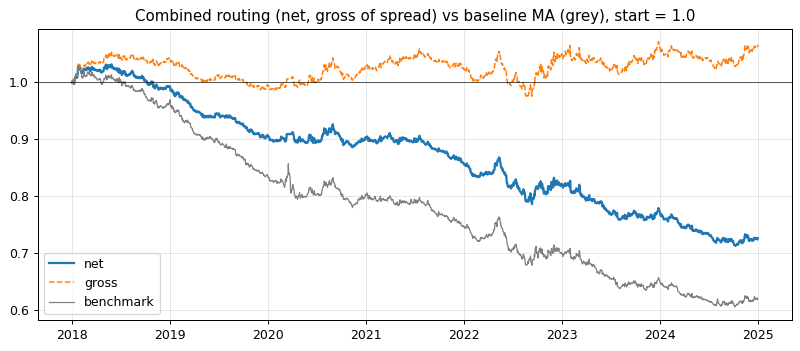

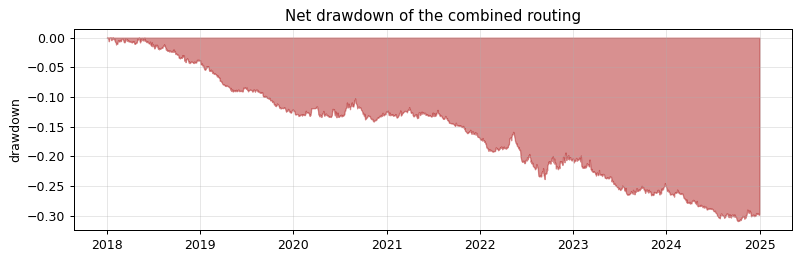

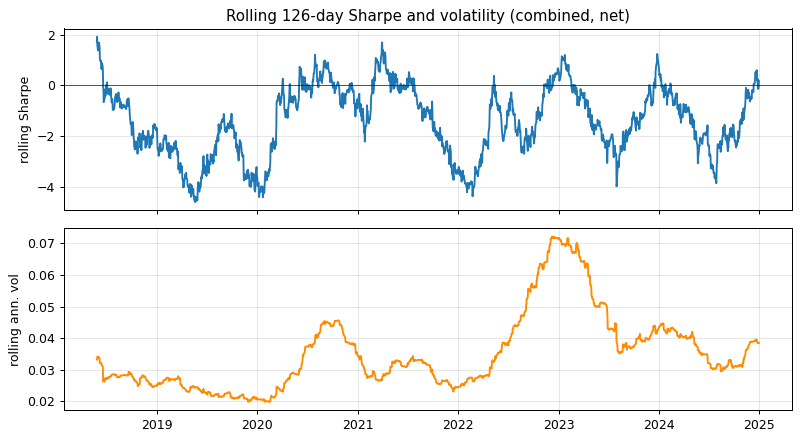

In [ ]:
base, comb = net["baseline_ma"], net["combined_cusum_adf_routing"]
fig = plot_equity(comb, gross=mid["combined_cusum_adf_routing"], benchmark=base,
                  title="Combined routing (net, gross of spread) vs baseline MA (grey), start = 1.0")
plt.show()
fig = plot_drawdown(comb, title="Net drawdown of the combined routing")
plt.show()
fig = plot_rolling_risk(comb, window=126, periods_per_year=ppy, title="Rolling 126-day Sharpe and volatility (combined, net)")
plt.show()

### 9.2 Calendar views, distribution, exposure and turnover

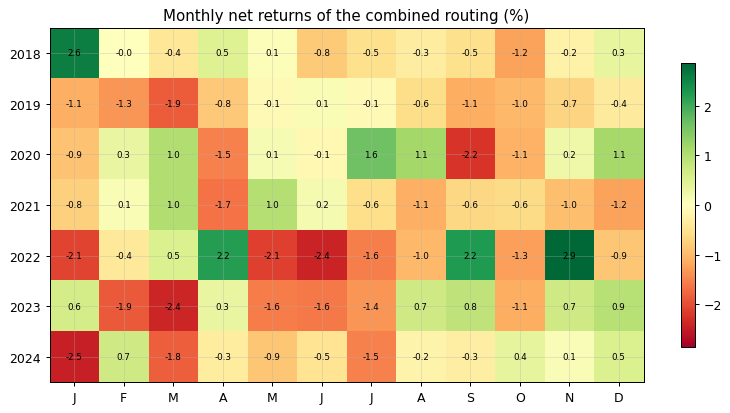

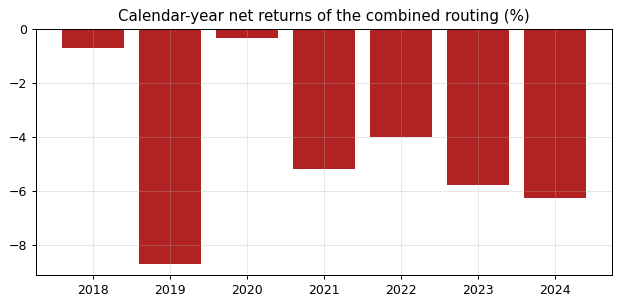

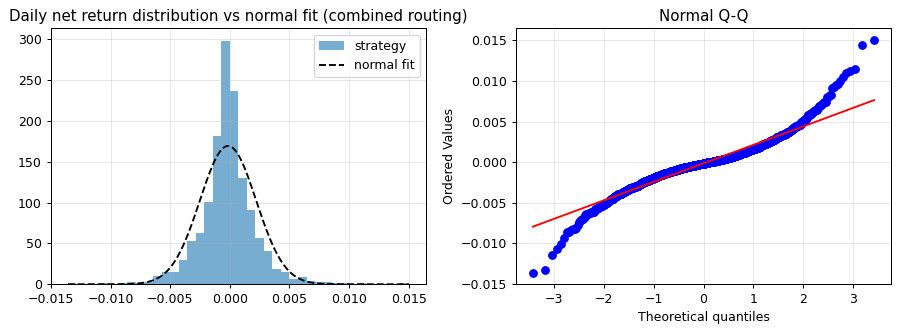

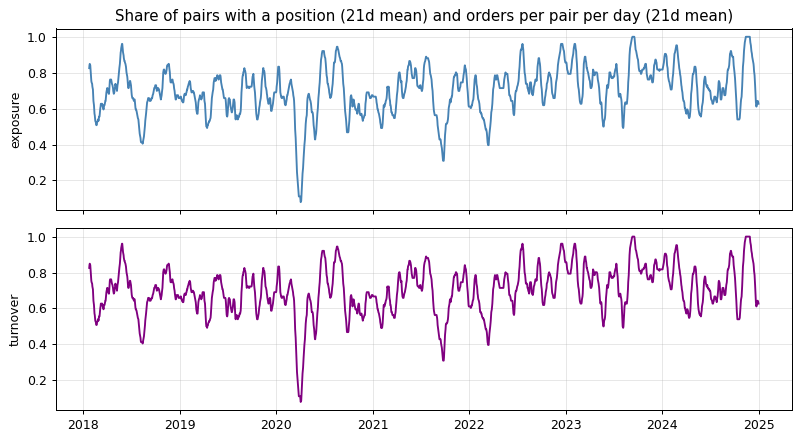

In [ ]:
fig = plot_monthly_heatmap(comb, title="Monthly net returns of the combined routing (%)")
plt.show()
fig = plot_yearly_bars(comb, title="Calendar-year net returns of the combined routing (%)")
plt.show()
fig = plot_return_distribution(comb, title="Daily net return distribution vs normal fit (combined routing)")
plt.show()
comb_tr = TRADES[(TRADES["strategy"] == "combined_cusum_adf_routing") & (TRADES["period"] == "development")]
exposure = comb_tr.groupby("date")["traded"].mean()
turnover = comb_tr.groupby("date")["traded"].sum() / len(PAIRS)
fig = plot_exposure_turnover(exposure.rolling(21).mean(), turnover.rolling(21).mean(),
                             title="Share of pairs with a position (21d mean) and orders per pair per day (21d mean)")
plt.show()
RESULTS["avg_exposure_combined"] = float(exposure.mean())

### 9.3 Where the P&L comes from: pair, year and regime

A strategy that loses everywhere has a different story from one that loses in one pair or one year. The three views below use the combined routing's development trades.

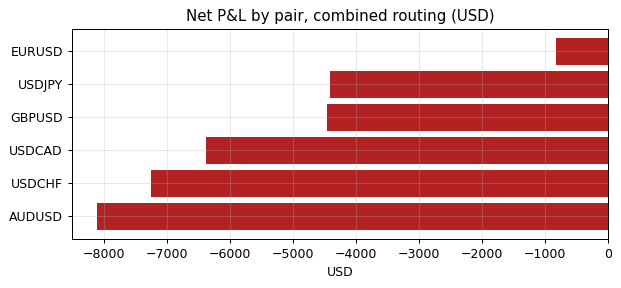

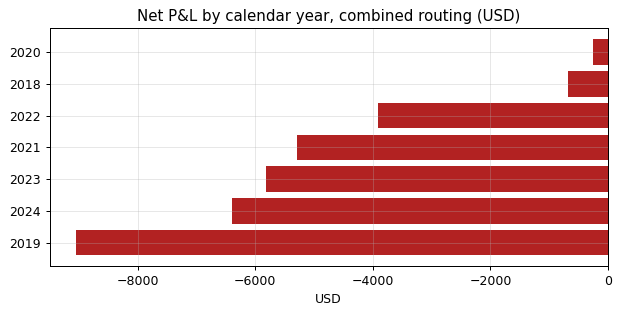

,count,mean_bp
regime,,
mean_reversion,17,-0.24
trend,9190,-2.05


In [ ]:
by_pair = comb_tr.groupby("pair")["net_return"].sum() / len(PAIRS) * float(PARAMS["capital"])
by_year = comb_tr.groupby(comb_tr["date"].dt.year)["net_return"].sum() / len(PAIRS) * float(PARAMS["capital"])
by_regime = comb_tr[comb_tr["traded"]].groupby("regime")["net_return"].agg(["count", "mean", "sum"])
fig = plot_bar_contribution(by_pair, title="Net P&L by pair, combined routing (USD)", xlabel="USD")
plt.show()
fig = plot_bar_contribution(by_year.rename(lambda y: str(int(y))), title="Net P&L by calendar year, combined routing (USD)", xlabel="USD")
plt.show()
by_regime["mean_bp"] = by_regime["mean"] * 1e4
display(by_regime[["count", "mean_bp"]].round(3))
RESULTS["pairs_positive_share"] = float((by_pair > 0).mean())
RESULTS["years_positive_share"] = float((by_year > 0).mean())

## 10. The killing test: how many independent regime events are there?

The hypothesis is conditional: *if* the detector finds a mean-reversion regime, fading the residual pays. To test a conditional claim you need enough events in the condition. Four measurements:

1. **Days and episodes.** How many days each pair spends in each regime, and how long an episode lasts.
2. **The funnel.** How many pair-days survive each filter on the way to a trade.
3. **Power.** With the observed number of mean-reversion trades and the observed dispersion of one-bar trade returns, what is the smallest average edge the data could detect, and how many trades would a modest edge need?
4. **Cluster interval.** A bootstrap that resamples *episodes*, not trades, because trades inside one episode are not independent.

regime,trend (% of days),mean_reversion (% of days),uncertain_flat (% of days)
EURUSD,69.99,1.27,28.74
GBPUSD,73.62,1.20,25.18
AUDUSD,72.60,0.25,27.14
USDCAD,69.26,0.87,29.87
USDCHF,67.59,1.05,31.36
USDJPY,68.17,0.40,31.43


regime,mean_reversion days
EURUSD,35
GBPUSD,33
AUDUSD,7
USDCAD,24
USDCHF,29
USDJPY,11


,count,min,median,max
label,,,,
mean_reversion,26,1,5.0,16
trend,560,1,17.0,136
uncertain_flat,584,1,6.0,42


,episodes,days,longest
pair,,,
AUDUSD,1,7,7
EURUSD,6,35,10
GBPUSD,5,33,16
USDCAD,5,24,9
USDCHF,6,29,8
USDJPY,3,11,5


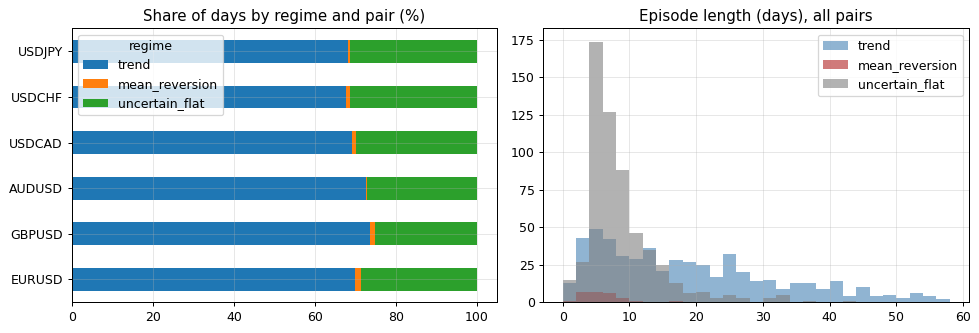

In [ ]:
EVAL = {pair: f[f.index >= pd.Timestamp(PARAMS["development_start"])] for pair, f in REGIMES.items()}
regime_days = pd.DataFrame({pair: f["regime"].value_counts() for pair, f in EVAL.items()}).fillna(0).astype(int).T
regime_days = regime_days.reindex(columns=["trend", "mean_reversion", "uncertain_flat"]).fillna(0).astype(int)
display((regime_days.div(regime_days.sum(axis=1), axis=0) * 100).round(2).add_suffix(" (% of days)"))
display(regime_days[["mean_reversion"]].rename(columns={"mean_reversion": "mean_reversion days"}))
episodes = []
for pair, f in EVAL.items():
    rl = run_length_table(f["regime"])
    rl["pair"] = pair
    episodes.append(rl)
episodes = pd.concat(episodes, ignore_index=True)
ep = episodes.groupby("label")["length"].agg(["count", "min", "median", "max"])
display(ep)
mr_ep = episodes[episodes["label"] == "mean_reversion"]
mr_by_pair = mr_ep.groupby("pair")["length"].agg(episodes="count", days="sum", longest="max")
display(mr_by_pair)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
(regime_days.div(regime_days.sum(axis=1), axis=0) * 100).plot.barh(stacked=True, ax=axes[0], legend=True)
axes[0].set_title("Share of days by regime and pair (%)")
for label, color in (("trend", "steelblue"), ("mean_reversion", "firebrick"), ("uncertain_flat", "grey")):
    axes[1].hist(episodes.loc[episodes["label"] == label, "length"], bins=np.arange(0, 60, 2), alpha=0.6, label=label, color=color)
axes[1].set_title("Episode length (days), all pairs")
axes[1].legend()
fig.tight_layout()
plt.show()
RESULTS.update({"mr_days_min": int(regime_days["mean_reversion"].min()), "mr_days_max": int(regime_days["mean_reversion"].max()),
                "mr_share_min_pct": float((regime_days["mean_reversion"] / regime_days.sum(axis=1)).min() * 100),
                "mr_share_max_pct": float((regime_days["mean_reversion"] / regime_days.sum(axis=1)).max() * 100), "mr_len_min": int(mr_ep["length"].min()),
                "mr_len_max": int(mr_ep["length"].max()), "mr_episodes": int(len(mr_ep))})

### 10.1 The funnel and the sensitivity of the count to the gate

Each column is a stricter filter on the same pair-days, over the evaluation window. The second table re-derives the regimes (no refit, no new ADF) with other per-test significance levels. This is a **diagnostic about the size of the sample, not a tuning step**: no level is chosen as the headline, and the development result of the design level is the one reported everywhere else. A `NaN` interval means fewer than 20 trades: the bootstrap refuses to give an interval from so few observations.

In [ ]:
start = pd.Timestamp(PARAMS["development_start"])
hold = pd.Timestamp(PARAMS["holdout_start"])
alpha_adj = PARAMS["adf_alpha"] / len(HEDGE_PAIR)
rows = []
for pair, f in REGIMES.items():
    g = f[(f.index >= start) & (f.index < hold)]
    p_ok = g["adf_p_value"] < alpha_adj
    hl_ok = g["half_life_days"].between(PARAMS["adf_min_half_life"], PARAMS["adf_max_half_life"])
    both = p_ok & hl_ok
    sup = g["adf_mean_reversion_support"]
    mr = g["regime"].eq("mean_reversion")
    n_tr = int(((TRADES["strategy"] == "combined_cusum_adf_routing") & (TRADES["period"] == "development")
                & TRADES["traded"] & (TRADES["regime"] == "mean_reversion") & (TRADES["pair"] == pair)).sum())
    rows.append({"pair": pair, "p_below_alpha": int(p_ok.sum()), "and_half_life_ok": int(both.sum()),
                 "and_5_day_streak": int(sup.sum()), "and_not_trend": int(mr.sum()), "and_abs_z_ge_entry": n_tr})
funnel = pd.DataFrame(rows).set_index("pair")
funnel.loc["all"] = funnel.sum()
display(funnel)
RESULTS["funnel_p_ok"] = int(funnel.loc["all", "p_below_alpha"])
RESULTS["funnel_trades"] = int(funnel.loc["all", "and_abs_z_ge_entry"])

sens = []
for label, a in (("design (0.05 / 6)", alpha_adj), ("0.05", 0.05), ("0.10", 0.10), ("0.20", 0.20)):
    regs = build_regime_frames(FRAMES, CUSUM, ADF, PARAMS, adjusted_alpha=a)
    tr = trade_table(regs, PARAMS)
    mr_tr = tr[(tr["strategy"] == "combined_cusum_adf_routing") & (tr["period"] == "development")
               & tr["traded"] & (tr["regime"] == "mean_reversion")]
    c = bootstrap_mean_ci(mr_tr["net_return"], n_boot=int(PARAMS["n_bootstrap"]), seed=int(PARAMS["random_seed"]), min_obs=20)
    comb_d = daily_portfolio(tr, "combined_cusum_adf_routing", "development")
    sens.append({"per_test_alpha": label, "mr_days": int(sum((f["regime"] == "mean_reversion").sum() for f in regs.values())),
                 "mr_trades_dev": int(len(mr_tr)), "mr_mean_bp": c["mean"] * 1e4 if len(mr_tr) else np.nan,
                 "ci95_lo_bp": c["lo"] * 1e4, "ci95_hi_bp": c["hi"] * 1e4, "combined_total_return": float((1 + comb_d).prod() - 1)})
sens = pd.DataFrame(sens).set_index("per_test_alpha")
display(sens.round(3))
RESULTS["sensitivity"] = sens.round(6).reset_index().to_dict("records")
RESULTS["mr_trades_dev"] = int(sens.loc["design (0.05 / 6)", "mr_trades_dev"])

,p_below_alpha,and_half_life_ok,and_5_day_streak,and_not_trend,and_abs_z_ge_entry
pair,,,,,
EURUSD,149,149,90,22,5
GBPUSD,139,139,96,33,3
AUDUSD,35,35,5,0,0
USDCAD,143,143,78,24,5
USDCHF,161,161,108,26,1
USDJPY,77,77,23,11,3
all,704,704,400,116,17


,mr_days,mr_trades_dev,mr_mean_bp,ci95_lo_bp,ci95_hi_bp,combined_total_return
per_test_alpha,,,,,,
design (0.05 / 6),139,17,-0.240,NaN,NaN,-0.274
0.05,672,93,-5.413,-13.912,2.575,-0.272
0.10,1169,148,-2.725,-10.559,4.693,-0.266
0.20,1981,216,-0.649,-7.147,5.282,-0.254


### 10.2 Power: what could 19-odd trades ever show?

The one-bar trade return has a dispersion `s` (measured on the development trades of the always-on baseline, which are plentiful). For `n` trades the standard error of the mean is `s / sqrt(n)`. A two-sided 5% test with 80% power detects a true mean of about `(1.96 + 0.84) x s / sqrt(n)`. The needed `n` for a given edge `e` is `((1.96 + 0.84) x s / e)^2`. These are normal-approximation numbers meant for orders of magnitude.

dispersion of one-bar trade return: 47.4 bp | mean-reversion trades: 17
smallest detectable mean per trade at 80% power: 32.2 bp
trades needed to detect an edge of 1, 2, 5, 10 bp: {1: '17,623', 2: '4,406', 5: '705', 10: '176'}
for scale: the commission add-on alone is 1.0 bp per round trip, plus the quoted spread
independent episodes with a trade: 11 (trades: 17)
episode-level bootstrap 95% interval of the mean trade return: [-15.9, 14.8] bp


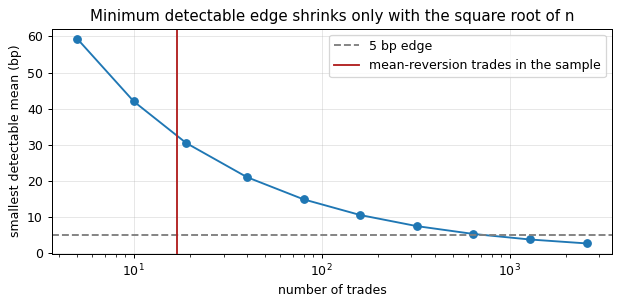

In [ ]:
base_tr = TRADES[(TRADES["strategy"] == "baseline_ma") & (TRADES["period"] == "development") & TRADES["traded"]]
s = float(base_tr["net_return"].std(ddof=1))
n_mr = int(RESULTS["mr_trades_dev"])
z = 1.96 + 0.84
mde = z * s / math.sqrt(max(n_mr, 1))
need = {e: (z * s / (e * 1e-4)) ** 2 for e in (1, 2, 5, 10)}
print(f"dispersion of one-bar trade return: {s * 1e4:.1f} bp | mean-reversion trades: {n_mr}")
print(f"smallest detectable mean per trade at 80% power: {mde * 1e4:.1f} bp")
print("trades needed to detect an edge of 1, 2, 5, 10 bp:", {k: f"{v:,.0f}" for k, v in need.items()})
cost_rt = 2 * PARAMS["commission_bps_per_order"] * PARAMS["cost_multiplier"]
print(f"for scale: the commission add-on alone is {cost_rt:.1f} bp per round trip, plus the quoted spread")
RESULTS.update({"trade_sd_bp": s * 1e4, "mde_bps": mde * 1e4, "n_needed_5bps": need[5], "n_needed_1bps": need[1]})

# cluster bootstrap: resample mean-reversion EPISODES, not trades
mr_all = TRADES[(TRADES["strategy"] == "combined_cusum_adf_routing") & (TRADES["period"] == "development")
                & TRADES["traded"] & (TRADES["regime"] == "mean_reversion")].copy()
ep_id = []
for _, row in mr_all.iterrows():
    r = episodes[(episodes["pair"] == row["pair"]) & (episodes["label"] == "mean_reversion")
                 & (episodes["start"] <= row["date"]) & (episodes["end"] >= row["date"])]
    ep_id.append(f"{row['pair']}-{r.index[0]}" if len(r) else "none")
mr_all["episode"] = ep_id
per_ep = mr_all.groupby("episode")["net_return"].mean()
rng = np.random.default_rng(int(PARAMS["random_seed"]))
boots = np.array([rng.choice(per_ep.to_numpy(), len(per_ep)).mean() for _ in range(int(PARAMS["n_bootstrap"]))]) if len(per_ep) > 1 else np.array([np.nan])
print(f"independent episodes with a trade: {len(per_ep)} (trades: {len(mr_all)})")
print(f"episode-level bootstrap 95% interval of the mean trade return: [{np.nanquantile(boots, 0.025) * 1e4:.1f}, {np.nanquantile(boots, 0.975) * 1e4:.1f}] bp")
RESULTS.update({"mr_trade_episodes": int(len(per_ep)), "ep_ci_lo_bp": float(np.nanquantile(boots, 0.025) * 1e4),
                "ep_ci_hi_bp": float(np.nanquantile(boots, 0.975) * 1e4)})
fig, ax = plt.subplots(figsize=(7, 3.5))
ns = np.array([5, 10, 19, 40, 80, 160, 320, 640, 1280, 2560])
ax.plot(ns, z * s / np.sqrt(ns) * 1e4, marker="o")
ax.axhline(5, color="grey", ls="--", label="5 bp edge")
ax.axvline(max(n_mr, 1), color="firebrick", label="mean-reversion trades in the sample")
ax.set_xscale("log")
ax.set_xlabel("number of trades")
ax.set_ylabel("smallest detectable mean (bp)")
ax.set_title("Minimum detectable edge shrinks only with the square root of n")
ax.legend()
fig.tight_layout()
plt.show()

### 10.3 Conditional expectancy and the decision rule

The decision rule fixed four hurdles in advance for the routed strategy in the development window: at least 120 trades overall; at least two regimes with 30 or more trades each and a positive post-cost expectancy in every such regime; a positive expectancy in at least 60% of pairs; and in at least 60% of calendar years. The cell below applies the same rule to this run.

In [ ]:
cond = (TRADES[TRADES["traded"] & (TRADES["strategy"] == "combined_cusum_adf_routing") & (TRADES["period"] == "development")]
        .groupby("regime")["net_return"].agg(trade_count="count", expectancy="mean"))
cond["expectancy_bp"] = cond["expectancy"] * 1e4
display(cond[["trade_count", "expectancy_bp"]].round(3))


def decision(trades: pd.DataFrame, p: Dict[str, Any]) -> Dict[str, Any]:
    g = trades[(trades["strategy"] == "combined_cusum_adf_routing") & (trades["period"] == "development") & trades["traded"]]
    reasons = []
    if len(g) < p["min_trades"]:
        reasons.append("combined development trade count is below the stated minimum")
    conditional = g.groupby("regime")["net_return"].agg(["count", "mean"])
    eligible = conditional[conditional["count"] >= p["min_conditional_trades"]]
    if len(eligible) < 2:
        reasons.append("fewer than two detected regimes have adequate conditional observations")
    elif not bool((eligible["mean"] > 0).all()):
        reasons.append("one or more adequately observed regimes has non-positive post-cost expectancy")
    pair_pos = g.groupby("pair")["net_return"].mean()
    year_pos = g.groupby(g["date"].dt.year)["net_return"].mean()
    if pair_pos.empty or float((pair_pos > 0).mean()) < p["stability_min"]:
        reasons.append("positive expectancy is not stable across at least 60% of pairs")
    if year_pos.empty or float((year_pos > 0).mean()) < p["stability_min"]:
        reasons.append("positive expectancy is not stable across at least 60% of calendar years")
    return {"passed": not reasons, "reasons": reasons}


DECISION = decision(TRADES, PARAMS)
print("decision:", "retain for independent fresh validation" if DECISION["passed"] else "retire or change the hypothesis")
for r in DECISION["reasons"]:
    print(" -", r)
RESULTS["decision_passed"] = bool(DECISION["passed"])
RESULTS["decision_reasons"] = DECISION["reasons"]

,trade_count,expectancy_bp
regime,,
mean_reversion,17,-0.24
trend,9190,-2.05


decision: retire or change the hypothesis
 - fewer than two detected regimes have adequate conditional observations
 - positive expectancy is not stable across at least 60% of pairs
 - positive expectancy is not stable across at least 60% of calendar years


## 11. Capital sweep and cost sensitivity

### 11.1 Capital sweep

The headline equity of 100,000 USD is an illustrative assumption, so the same development record is re-read at six equity levels. **Only the initial equity changes**: signals, detectors, costs and windows are identical and nothing is retuned. This strategy sizes every pair at a fixed notional share of equity and its costs are proportional (spread and a bps commission), so there is no per-order minimum to bite. Every *ratio* is therefore identical at every level, and the USD figures scale linearly. The table makes that explicit rather than assuming it.

capital,5000,10000,25000,50000,100000,250000
gross_usd,328.964,657.929,1644.821,3289.643,6579.285,16448.213
net_usd,-1370.063,-2740.126,-6850.316,-13700.631,-27401.262,-68503.155
cost_usd,1699.027,3398.055,8495.137,16990.274,33980.547,84951.368
net_return,-27.401,-27.401,-27.401,-27.401,-27.401,-27.401
cost_share,33.981,33.981,33.981,33.981,33.981,33.981
sharpe,-0.968,-0.968,-0.968,-0.968,-0.968,-0.968
max_drawdown,-30.883,-30.883,-30.883,-30.883,-30.883,-30.883


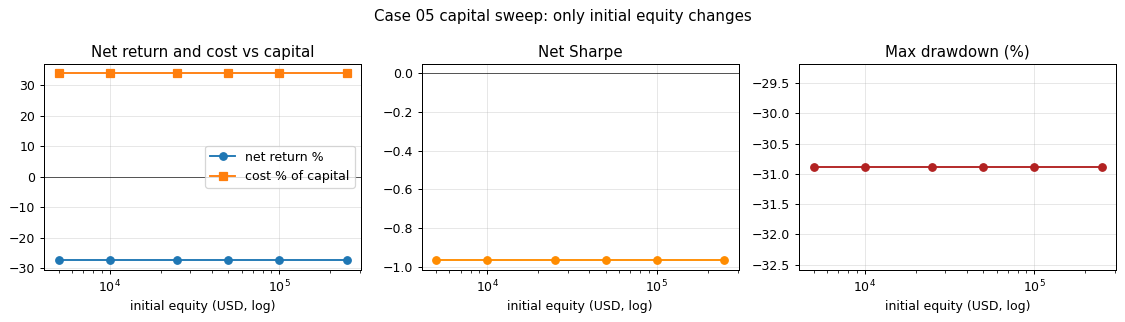

In [ ]:
dev_net = net["combined_cusum_adf_routing"]
dev_gross = mid["combined_cusum_adf_routing"]


def run_at_capital(cap: float) -> Dict[str, float]:
    eq = cap * (1.0 + dev_net).cumprod()
    sm = performance_summary(dev_net, periods_per_year=ppy)
    gross_usd = float(cap * ((1.0 + dev_gross).prod() - 1.0))
    net_usd = float(eq.iloc[-1] - cap)
    return {"gross_usd": gross_usd, "net_usd": net_usd, "cost_usd": gross_usd - net_usd, "net_return": net_usd / cap,
            "cost_share": (gross_usd - net_usd) / cap, "sharpe": float(sm["sharpe"]), "max_drawdown": float(sm["max_drawdown"])}


_caps = [5_000, 100_000] if SYNTHETIC else [5_000, 10_000, 25_000, 50_000, 100_000, 250_000]
cap_sweep = capital_sweep(run_at_capital, _caps)
show = cap_sweep.copy()
for col in ["net_return", "cost_share", "max_drawdown"]:
    show[col] = (show[col] * 100).round(3)
display(show.round(3).set_index("capital").T)
plot_capital_sweep(cap_sweep, title="Case 03 capital sweep: only initial equity changes")
plt.show()
RESULTS["capital_sweep"] = cap_sweep.round(6).to_dict("records")
RESULTS["sweep_net_return_spread"] = float(cap_sweep["net_return"].max() - cap_sweep["net_return"].min())

### 11.2 Cost multiplier

The spread is a property of the quotes; the commission add-on is the only cost constant set by assumption. Scaling **only the commission add-on** (the quoted spread stays as observed) shows whether any plausible commission level changes the verdict. A multiplier of 0 removes the add-on but not the spread.

In [ ]:
rows = []
for m in (0.0, 1.0, 2.0, 4.0):
    p2 = dict(PARAMS, cost_multiplier=m)
    r2 = run_pipeline(REGIMES, p2)["summary"]
    d2 = r2[r2["period"] == "development"].set_index("strategy")
    rows.append({"commission_multiplier": m, **{f"{k}_total_return": float(d2.loc[k, "total_return"]) for k in ("baseline_ma", "combined_cusum_adf_routing")},
                 **{f"{k}_sharpe": float(d2.loc[k, "sharpe"]) for k in ("baseline_ma", "combined_cusum_adf_routing")}})
cost_sweep = pd.DataFrame(rows).set_index("commission_multiplier")
display(cost_sweep.round(4))
RESULTS["cost_sweep"] = cost_sweep.round(6).reset_index().to_dict("records")
RESULTS["baseline_total_comm0"] = float(cost_sweep.loc[0.0, "baseline_ma_total_return"])
RESULTS["combined_total_comm0"] = float(cost_sweep.loc[0.0, "combined_cusum_adf_routing_total_return"])
RESULTS["baseline_total_comm4"] = float(cost_sweep.loc[4.0, "baseline_ma_total_return"])

,baseline_ma_total_return,combined_cusum_adf_routing_total_return,baseline_ma_sharpe,combined_cusum_adf_routing_sharpe
commission_multiplier,,,,
0.0,-0.2278,-0.1536,-0.6188,-0.4952
1.0,-0.3794,-0.2740,-1.1618,-0.9679
2.0,-0.5013,-0.3773,-1.7048,-1.4402
4.0,-0.6780,-0.5419,-2.7907,-2.3834


## 12. Interpretation

**Headline, at 100,000 USD of illustrative equity.** In the development window the baseline moving-average rule returns -37.9% net (-37,944 USD) with an annualised Sharpe of -1.16, a maximum drawdown of -41.2% and 13,116 pair-day trades. The CUSUM/ADF routing returns -27.4% (-27,401 USD), Sharpe -0.97, maximum drawdown -30.9%, on 9,207 trades. The routed strategy is a smaller version of the baseline, not a better one. Gross of the quoted spread and the commission add-on (mid-to-mid) the two records are 7.4% and 6.6%: the routing mostly reduces exposure, and what it keeps still loses after executable prices. The retrospective window tells the same story (-21.1% for the baseline and -12.7% for the routing), and it was not used for any choice.

**The mean-reversion branch is starved.** Across the six pairs the mean-reversion regime exists on only 7 to 35 days per pair, in 26 episodes of 1 to 16 days. The funnel shows where the days go: the Bonferroni-adjusted ADF level is passed on 704 development pair-days, and after the half-life bounds, the five-day streak, the trend veto and the entry threshold only 17 remain. That is 17 development trades in 11 independent episodes. With a one-bar trade dispersion of about 47 basis points the smallest edge this sample could detect is 32 basis points per trade; a 5 basis point edge would need about 705 trades and a 1 basis point edge about 17,623. The episode-level bootstrap interval of the mean trade return, [-16, 15] basis points, is the honest picture: it contains every economically interesting value, positive and negative.

**Loosening the gate does not rescue it.** Section 10.1 re-derives the regimes at weaker per-test significance levels. More days qualify and the trade count grows, but the mean trade return stays negative at every level tried and its bootstrap interval contains zero. This is a diagnostic of the sample size, not an invitation to tune: any level chosen after seeing this table would be selected with the same data.

**The decision rule agrees.** The rule fails on the number of regimes with adequate observations and on stability across pairs and across years. (The overall trade-count hurdle is passed only because the trend branch is the baseline and trades thousands of times.) The rule's recommendation is to retire or change the hypothesis; the more useful reading is that the hypothesis was never tested.

**Capital does not matter; costs do.** The capital sweep returns identical ratios at every level (the largest difference in net return across the sweep is 5.6e-17), because nothing in the strategy has a per-order minimum. The cost story is in the gross figures. Mid-to-mid the baseline is 7.4%; paying the quoted bid/ask spread alone (commission multiplier 0 in section 11.2) takes the executable record to -22.8%, and the 1 basis point per round trip commission add-on takes it to -37.9%. The sign of the net result does not change anywhere in the commission sweep (-67.8% at four times the add-on).

**Honest label.** Regime starvation is the primary tag because the routed strategy's novel branch has too few independent events to estimate anything. The secondary tag, cost model, reflects that the baseline it routes is slightly positive mid-to-mid and loses heavily once it pays executable prices, so even the part of the strategy that trades enough to be measured has no net edge.

## 13. The lesson

**Count the events behind each branch before you read the P&L of the whole.** A regime router is two (or more) strategies glued together; its blended record is dominated by whichever branch trades most, here the trend branch, which is simply the baseline. Report, for each regime, how many independent episodes exist, how long they last and the smallest edge the sample could detect. If the answer is "a few dozen trades in a handful of episodes", the right conclusion is "no test was possible", and no amount of post-cost arithmetic on the blended curve changes that.

## 14. What I would do differently

* **Compute the power table first.** The funnel and the minimum detectable edge take minutes and would have shown that the mean-reversion branch could not be tested before any P&L was computed.
* **Choose the regime definition for event count, not for purity.** A 120-day rolling ADF with a Bonferroni level and a five-day streak is a very strict definition. A looser, pre-registered definition (or a longer history across many more pairs) would produce an estimable number of episodes.
* **Pool across instruments or frequencies.** Six pairs and one daily cadence give a handful of episodes. Intraday bars or a broader cross-section raise the count by orders of magnitude.
* **Test the trend branch against its own baseline separately.** If the gate only removes exposure, say so and compare with a volatility-scaled baseline of the same average exposure.

## 15. How to improve it (ideas, not claims)

* Replace the rolling ADF with a regression on a half-life estimate that has a published sampling error, and require the *interval* to exclude the no-reversion region.
* Estimate the hedge ratio on a longer window than the test window, so the test statistic does not use the same 120 observations twice.
* Use executable minute prices for the entry and exit instead of daily bid/ask closes.
* Add pairs and a second cadence so the number of independent mean-reversion episodes is in the hundreds.

## 16. FAQ

**Is the mean-reversion idea wrong?** This record cannot say. It has too few events to support or reject it; that is the finding.

**Why is the baseline so bad?** Executable prices make a daily moving-average rule pay the quoted spread on every flip, and a trend rule that flips often on mean-reverting FX pairs gives most of it back. Section 8 shows the gross-of-spread record for comparison.

**Why a Bonferroni correction over six pairs?** The router tests six related-pair candidates; without a correction a 5% level would fire on roughly one day in twenty by chance on every pair, and the router would act on noise. The same correction is what makes the branch so rare.

**Is the retrospective window out-of-sample?** No. It had been looked at before this write-up; it is reported separately and was never used for a choice, but it is not fresh validation.

**Does the failure reproduce in synthetic mode?** No. Synthetic data are driftless random walks with a shared factor; the regime counts and the P&L have no relationship to the real run.

## 17. References

* Page, E. S. (1954). Continuous inspection schemes. *Biometrika*, 41, 100-115.
* Dickey, D. A. and Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association*, 74, 427-431.
* Engle, R. F. and Granger, C. W. J. (1987). Co-integration and error correction. *Econometrica*, 55, 251-276.
* Bailey, D. H. and Lopez de Prado, M. (2014). The deflated Sharpe ratio. *Journal of Portfolio Management*.
* Efron, B. and Tibshirani, R. (1993). *An Introduction to the Bootstrap.* Chapman and Hall.

## 18. Disclaimer

This notebook is educational. It documents a failed research experiment and is not financial advice or a recommendation to trade any instrument. Leveraged FX trading involves substantial risk of loss. Past or hypothetical results do not predict future results. The same-period-close execution assumption is a modelling simplification, not evidence of live fill quality. The code is provided as is, without warranty.

In [ ]:
if os.environ.get("AUTOPSY_RESULTS_JSON"):
    Path(os.environ["AUTOPSY_RESULTS_JSON"]).write_text(json.dumps(RESULTS, indent=2, default=str))
print("done")

done
